## C1 - WEEK 4

- Adrià Cantarero Carreras  (1809773@uab.cat)
- Ivan Martin Campoy (1673246@uab.cat)
- Irene Pumares Benaiges (1810704@uab.cat)
- Lavish Ramchandani (1691238@uab.cat)

In [35]:
import sys
sys.path.append("..")  # repo root, for utils/
#needed libraries

import os
import re
import cv2
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## Common pipeline (from Week 3)

Every photo goes through the same steps before the local descriptors:

1. Denoising (Week 3, Task 1): impulse / additive noise detector, median 3x3 only on the photos detected as noisy.
2. Painting detection (Week 3, Task 3): wall colour model in Lab (Week 2 method C) + hole filling + connected components, with two small changes for the test set, explained in that section.
3. Crop the bounding box of every painting from the denoised photo.
4. Local descriptors + matching (Tasks 1-2, next sections) give a score per BBDD image for every crop.
5. Output: for every photo, one list per painting with the top-10 BBDD ids, or `[-1]` if the painting is unknown.

Only the selected configuration of every Week 3 step is copied here.

### Data

In [36]:
#paths and results folder
bbdd_path = "./data/BBDD"
qsd1_path = "./data/qsd1_w4"
results_dir = "./results"
os.makedirs(results_dir, exist_ok=True)

def read_image(img_path):
    image = cv2.imread(img_path)
    if image is None:
        raise IOError(f"Could not read {img_path}")
    return image

#sort files in natural order
def return_number(string):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', string)]

def load_query_set(folder):
    files = sorted([f for f in os.listdir(folder) if f.lower().endswith(".jpg")], key=return_number)
    return files, [read_image(os.path.join(folder, f)) for f in files]

def load_pickle(path):
    #None if the file is not in the dataset
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)

def as_id_list(g):
    #one ground truth entry -> list of int bbdd ids (one per painting, -1 = not in the museum)
    return [int(x) for x in g] if isinstance(g, (list, tuple, np.ndarray)) else [int(g)]

#type of every photo (only used to analyse the results, never to retrieve)
def aug_type(a):
    a = str(a).lower()
    if "noise" in a:
        return "noise"
    if "color" in a or "hue" in a:
        return "color"
    return "none"

#museum
bbdd_files, bbdd_imgs = load_query_set(bbdd_path)
bbdd_ids = np.array([int(re.findall(r"\d+", f)[-1]) for f in bbdd_files]) #bbdd_00012.jpg -> 12
bbdd_index = {b: i for i, b in enumerate(bbdd_ids)} #bbdd id -> position in bbdd_imgs

#QSD1-W4 photos and ground truth (correct answers): one bbdd id per painting, left to right (-1 = painting not in the museum)
qsd1_files, qsd1_imgs = load_query_set(qsd1_path)
qsd1_gt = [as_id_list(g) for g in load_pickle(os.path.join(qsd1_path, "gt_corresps.pkl"))]
qsd1_n_paintings = np.array([len(g) for g in qsd1_gt])

#optional files (only to analyse the results)
qsd1_augs = load_pickle(os.path.join(qsd1_path, "augmentations.pkl"))
qsd1_type = np.array([aug_type(a) for a in qsd1_augs]) if qsd1_augs is not None else None
mask_paths = [os.path.join(qsd1_path, os.path.splitext(f)[0] + ".png") for f in qsd1_files]
qsd1_gt_masks = [cv2.imread(p, cv2.IMREAD_GRAYSCALE) > 0 for p in mask_paths] if all(map(os.path.exists, mask_paths)) else None

n_unknown = sum(g.count(-1) for g in qsd1_gt)
print(f"BBDD: {len(bbdd_imgs)} images")
print(f"QSD1-W4: {len(qsd1_imgs)} photos, {qsd1_n_paintings.sum()} paintings "
      f"({np.sum(qsd1_n_paintings == 2)} photos with two), {n_unknown} paintings not in the museum")
if qsd1_type is not None:
    print("photo types:", pd.Series(qsd1_type).value_counts().to_dict())
print("Ground truth masks available:", qsd1_gt_masks is not None)

BBDD: 287 images
QSD1-W4: 30 photos, 39 paintings (9 photos with two), 10 paintings not in the museum
photo types: {'color': 12, 'none': 9, 'noise': 9}
Ground truth masks available: True


### Denoising (Week 3, Task 1)

Copied without changes: the thresholds were chosen on QSD1-W3 and the filter is the best one of the Week 3 comparison (median 3x3, best PSNR and SSIM). The median filter is only applied to the photos detected as noisy.

In [37]:
# Additive noise (a small random value added to each pixel)

LAPLACIAN_DIFF = np.array([[1, -2, 1],
                           [-2, 4, -2],
                           [1, -2, 1]], dtype=np.float64)

def additive_noise(img):
    sigmas = []
    for c in range(img.shape[2]):
        residual = cv2.filter2D(img[..., c].astype(np.float64), -1, LAPLACIAN_DIFF)[1:-1, 1:-1]   #drop the border (padding)
        sigmas.append(np.median(np.abs(residual)) / (0.6745 * 6))
    return np.mean(sigmas)

# Impulse noise (a pixel is replaced by a random value)

T_ISOLATED = 30 #grey levels a pixel must stand out from all its neighbours (~10% of the 0-255 range)
RING = np.ones((3, 3), np.uint8)
RING[1, 1] = 0 #structuring element = the 8 neighbours, without the centre pixel

def impulsive_noise(img, t=T_ISOLATED):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.int16)
    neigh_max = cv2.dilate(gray, RING) #max of the 8 neighbours
    neigh_min = cv2.erode(gray, RING) #min of the 8 neighbours
    return np.mean((gray > neigh_max + t) | (gray < neigh_min - t))

ISOLATED_THRESHOLD = 0.01 #fraction of isolated pixels
SIGMA_THRESHOLD = 8.0 #estimated noise std

def is_noisy(img):
    if impulsive_noise(img) > ISOLATED_THRESHOLD:
        return True
    if additive_noise(img) > SIGMA_THRESHOLD:
        return True
    return False

def denoise(img):
    #median 3x3 (best filter of Week 3) only if the photo is detected as noisy
    return cv2.medianBlur(img, 3) if is_noisy(img) else img

In [38]:
qsd1_detected = np.array([is_noisy(img) for img in qsd1_imgs])
qsd1_denoised = [denoise(img) for img in qsd1_imgs]
print("Detected as noisy:", [qsd1_files[i] for i in np.where(qsd1_detected)[0]])

#check with the real labels (only here, never used to decide)
if qsd1_type is not None:
    really_noisy = qsd1_type == "noise"
    print(f"Correctly detected: {np.sum(qsd1_detected & really_noisy)}/{really_noisy.sum()}")
    print(f"False positives: {np.sum(qsd1_detected & ~really_noisy)}/{np.sum(~really_noisy)}")

Detected as noisy: ['00003.jpg', '00008.jpg', '00012.jpg', '00017.jpg', '00019.jpg', '00022.jpg', '00023.jpg', '00024.jpg', '00025.jpg']
Correctly detected: 9/9
False positives: 0/21


### Painting detection (Week 3, Task 3)

Same method as Week 3: we learn the wall colour from the outer 3% of the photo, every pixel with a colour different enough from the wall is painting, then we fill the holes and keep the big connected components (at least 5% of the photo).

Two small changes, marked with `NEW` in the code. On QSD1-W4 they give the same result as Week 3, they are there so the method also works on the test set (QST1-W4):

1. Any number of paintings (`MAX_PAINTINGS = None`). Week 3 kept at most 2. QSD1-W4 has at most 2 paintings per photo, but the test set says "more than one picture per image", so it may have 3.
2. Order of the paintings (`ORDER = "auto"`). In Week 3 the paintings were always side by side, so we sorted them by their left edge. When one painting is above the other, both start at almost the same left edge and the order is random, so we sort them from top to bottom.

In [39]:
from functools import cmp_to_key

BORDER_RATIO = 0.03 #outer 3% of each side is assumed to be wall
W2_PARAMS = dict(tau=10, tau2=1.5, rho=0.6) #best Week 2 configuration (Lab, method C)
MIN_AREA = 0.05 #a painting covers at least 5% of the photo
MAX_PAINTINGS = None #NEW: None = any number of paintings (Week 3: 2)
ORDER = "auto" #NEW: "left-right" (Week 3) or "auto" (top to bottom when one painting is above the other)

def border_region(shape, border_ratio=BORDER_RATIO):
    #boolean map of the outer strip of the photo
    h, w = shape[:2]
    bh, bw = max(1, round(border_ratio * h)), max(1, round(border_ratio * w))
    region = np.zeros((h, w), dtype=bool)
    region[:bh, :] = True
    region[-bh:, :] = True
    region[:, :bw] = True
    region[:, -bw:] = True
    return region

def wall_colour_mask(image, tau=10, tau2=1.5, rho=0.6):
    #Week 2 method C in Lab: True = painting
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB).astype(np.float32)
    chroma, luma = lab[..., 1:], lab[..., 0]
    border = border_region(luma.shape)
    dist = np.sqrt(np.sum((chroma - np.median(chroma[border], axis=0)) ** 2, axis=-1)) #colour distance to the wall
    ratio = luma / (np.median(luma[border]) + 1e-6) #light relative to the wall
    return (dist > tau) | ((ratio < rho) & (dist > tau2))

def fill_holes(mask):
    #flood the background from the border; whatever background is not reached is a hole
    padded = np.pad(mask.astype(np.uint8), 1, constant_values=0)
    ff_mask = np.zeros((padded.shape[0] + 2, padded.shape[1] + 2), np.uint8)
    cv2.floodFill(padded, ff_mask, (0, 0), 1)
    return mask.astype(bool) | (padded[1:-1, 1:-1] == 0)

def reading_order(a, b, order=ORDER):
    #NEW: which of two paintings goes first in the result
    #why: with one painting above the other, the left edge gives a random order (both start almost at the same x)
    #"auto": if the two paintings share most of their horizontal range (one is above the other), the top one goes first
    #otherwise, the left one goes first (as in Week 3)
    if order == "auto":
        x_overlap = min(a[2], b[2]) - max(a[0], b[0])
        if x_overlap > 0.5 * min(a[2] - a[0], b[2] - b[0]):
            return a[1] - b[1]
    return a[0] - b[0]

def painting_regions(mask, min_area=MIN_AREA, max_paintings=MAX_PAINTINGS, order=ORDER):
    #the largest components (at most max_paintings, None = no limit) with at least min_area of the photo, in order (see reading_order)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    keep = [1 + k for k in np.argsort(-areas) if areas[k] >= min_area * mask.size]
    if max_paintings is not None:
        keep = keep[:max_paintings]
    box = lambda label: (stats[label, 0], stats[label, 1], stats[label, 0] + stats[label, 2], stats[label, 1] + stats[label, 3])
    keep.sort(key=cmp_to_key(lambda l1, l2: reading_order(box(l1), box(l2), order)))
    return [labels == label for label in keep]

def segment_paintings(image, min_area=MIN_AREA, max_paintings=MAX_PAINTINGS, order=ORDER):
    #-> list of boolean masks, one per painting, in order (see reading_order)
    regions = painting_regions(fill_holes(wall_colour_mask(image, **W2_PARAMS)), min_area, max_paintings, order)
    return regions if regions else [np.ones(image.shape[:2], dtype=bool)] #nothing found: the whole photo

def union(regions):
    #one mask with all the paintings of the photo
    return np.any(regions, axis=0)

def bbox_crop(image, region):
    ys, xs = np.nonzero(region)
    return image[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

def draw_regions(image, regions, gt=None):
    #detected paintings: light colour + outline + order number; correct mask outline in green
    colours = [(255, 120, 0), (0, 120, 255), (170, 0, 255), (255, 0, 120)]
    out = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).copy()
    thick = max(2, image.shape[1] // 250)
    for k, r in enumerate(regions):
        c = colours[k % len(colours)]
        out[r] = (0.75 * out[r] + 0.25 * np.array(c)).astype(np.uint8)
        cnts, _ = cv2.findContours(r.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, c, thick)
        ys, xs = np.nonzero(r)
        cv2.putText(out, str(k + 1), (int(xs.mean()), int(ys.mean())), cv2.FONT_HERSHEY_SIMPLEX,
                    image.shape[1] / 300, c, 3 * thick)
    if gt is not None:
        cnts, _ = cv2.findContours(gt.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, (0, 255, 0), thick)
    return out

In [46]:
EPS = 1e-10

def mask_prf(pred, gt):
    tp = np.count_nonzero(pred & gt)
    fp = np.count_nonzero(pred & ~gt)
    fn = np.count_nonzero(~pred & gt)
    p, r = tp / (tp + fp + EPS), tp / (tp + fn + EPS)
    return p, r, 2 * p * r / (p + r + EPS)

def evaluate_segmentation(regions):
    #right number of paintings per photo and, if the correct masks are available, pixel precision / recall / F1
    count_ok = np.array([len(r) == n for r, n in zip(regions, qsd1_n_paintings)])
    out = {"Right count": count_ok.sum()}
    if qsd1_gt_masks is not None:
        p, r, f1 = np.mean([mask_prf(union(rr), g) for rr, g in zip(regions, qsd1_gt_masks)], axis=0)
        out.update({"Precision": p, "Recall": r, "F1": f1})
    return out

qsd1_regions = [segment_paintings(img) for img in qsd1_denoised]
df_seg = pd.DataFrame([evaluate_segmentation(qsd1_regions)])
df_seg.to_csv(os.path.join(results_dir, "pipeline_segmentation.csv"), index=False)
display(df_seg.round(4))
wrong_count = [(qsd1_files[i], len(r), int(n)) for i, (r, n) in enumerate(zip(qsd1_regions, qsd1_n_paintings)) if len(r) != n]
print("photos with a wrong number of paintings (file, found, correct):", wrong_count)

per_photo = pd.DataFrame([{"file": f, **dict(zip(["Precision", "Recall", "F1"], mask_prf(union(r), g)))}
                          for f, r, g in zip(qsd1_files, qsd1_regions, qsd1_gt_masks)])
display(per_photo.sort_values("F1").head(6).round(3))

,Right count,Precision,Recall,F1
0,26,0.9463,0.8884,0.8976


photos with a wrong number of paintings (file, found, correct): [('00016.jpg', 1, 2), ('00020.jpg', 1, 2), ('00026.jpg', 2, 1), ('00028.jpg', 1, 2)]


,file,Precision,Recall,F1
17,00017.jpg,0.885,0.102,0.183
26,00026.jpg,0.998,0.392,0.563
28,00028.jpg,0.968,0.539,0.692
11,00011.jpg,0.995,0.741,0.849
2,00002.jpg,0.898,0.814,0.854
16,00016.jpg,0.951,0.790,0.863


- 26 of the 30 photos have the right number of paintings. The masks are worse than in QSD2-W3 (F1 0.898 against 0.967) because of the low recall (0.888). It comes from two problems (see the photos with the lowest F1 above):
  - Paintings not found: the white drawings on the white wall (right painting of 00016, top painting of 00028). Their colour is almost the same as the wall, so the colour rule only keeps small pieces of the frame and the drawing, too small to count as a painting. Same problem as 00002 in Week 3.
  - Paintings only partly found: 00017 (only 10% of the painting, its white stripes have the colour of the wall), 00026 (39%, the grey tiles have the colour of the wall, and the part found is cut in two pieces), 00011 (74%) and the left painting of 00002. In 00017 the number of paintings is right, so it does not appear in the list of wrong counts.
- 00020: the two paintings are found as one region, so they end up in the same crop.
- Cost for the retrieval: at least 4 of the 39 paintings will be wrong whatever descriptor we use (280 in 00016, 47 and 13 in 00028, and one of the two in 00020), so the best possible map@1 is about 35/39 = 0.90.
- 00017, 00026 and 00011, the photos with the worst partial masks, are paintings that are not in the museum, so on QSD1-W4 they do not cost anything in the retrieval. But they make the unknown detection easier than it should be: a small crop has few details, so it gets few matches and looks "unknown" partly because the crop is small. A painting of the museum found as badly in the test set would look unknown too.
- With the local descriptors (next sections), a mask that cuts part of the painting or keeps some wall should not be a big problem: they look for small details of the painting, and a cut painting still has many of them. We will check it in Task 3. But a painting that is not found, or two paintings in the same crop, cannot be fixed by the descriptors.

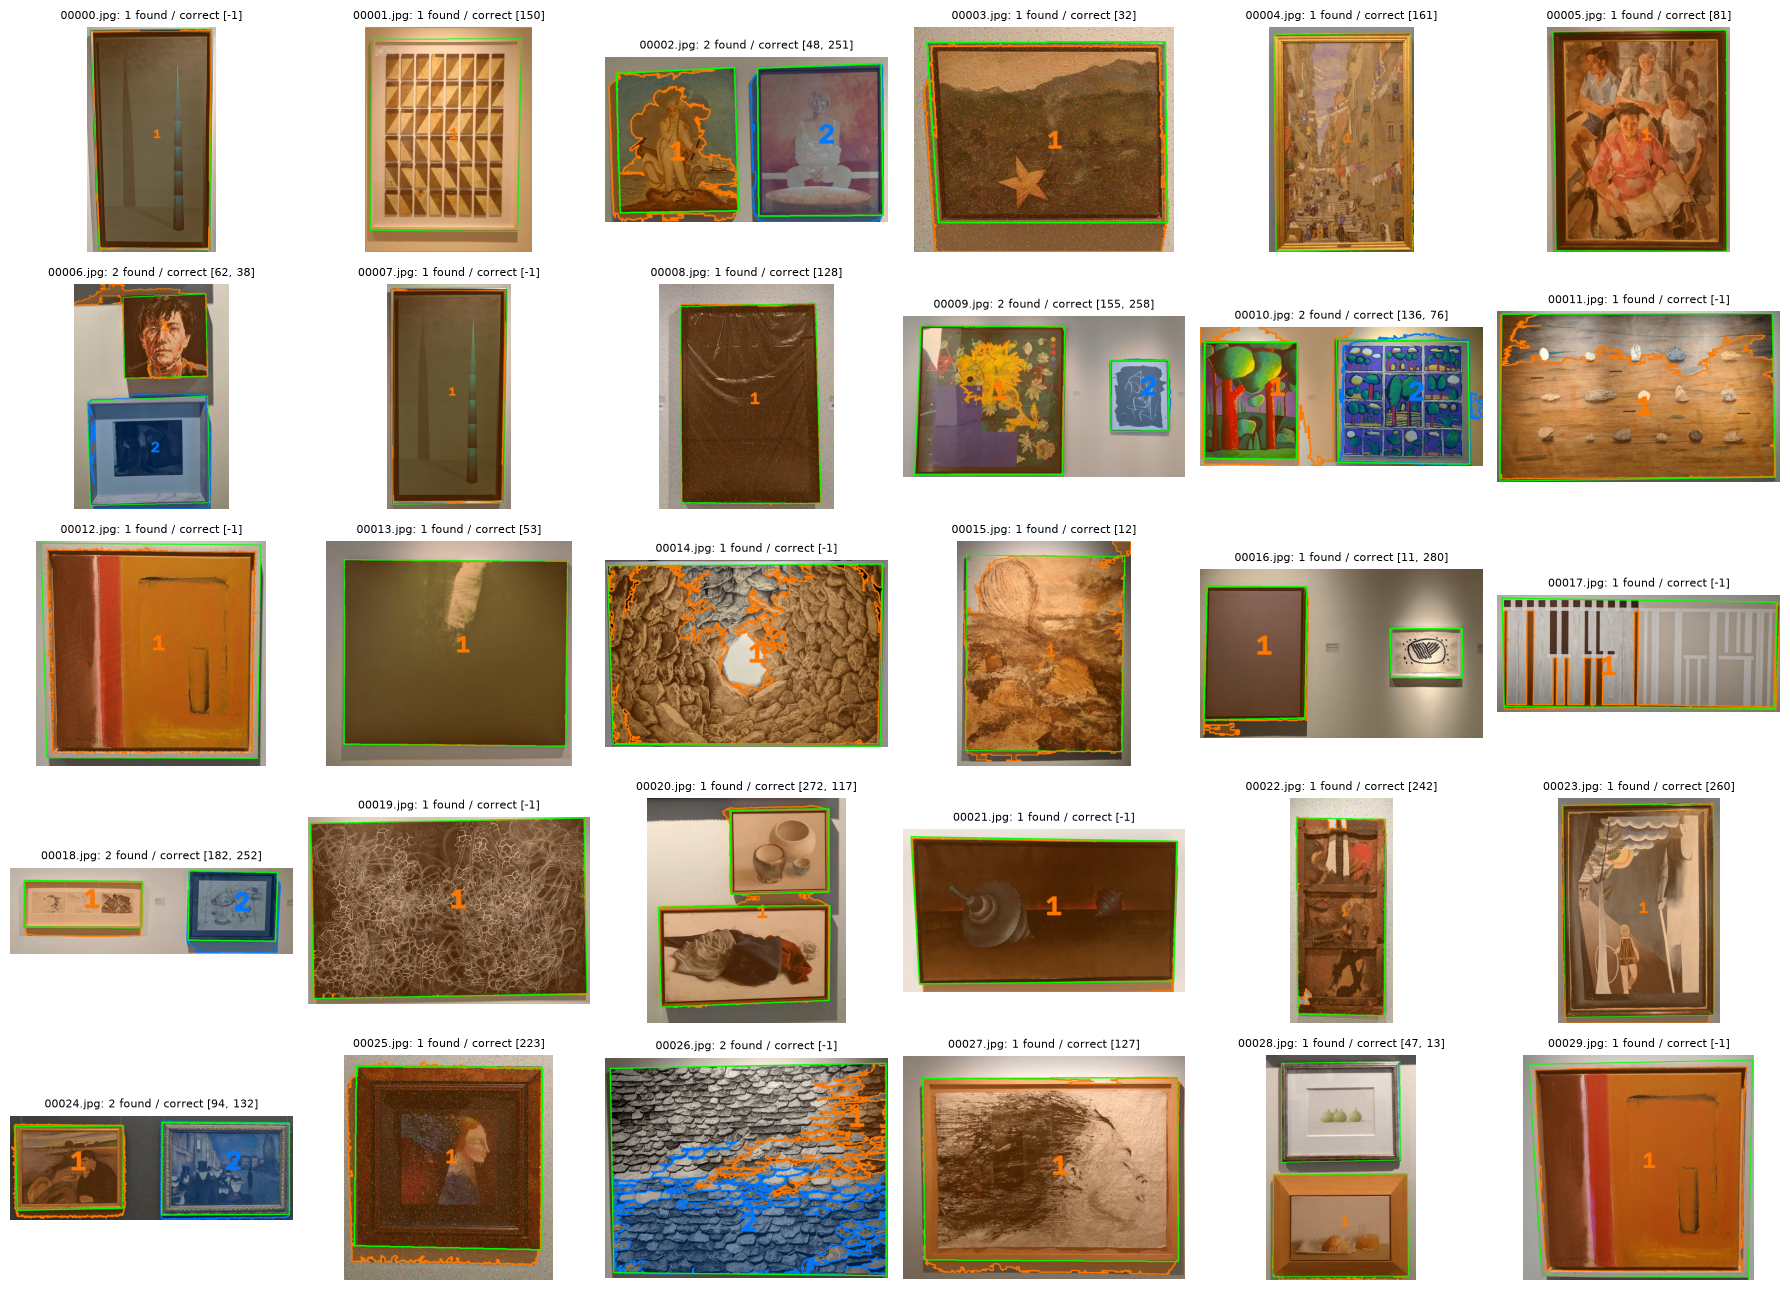

In [41]:
#visual check: every QSD1-W4 photo with its detected paintings (number = our order, correct mask outline in green)
n_cols = 6
n_rows = int(np.ceil(len(qsd1_files) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 2.6 * n_rows), squeeze=False)
for i, ax in enumerate(axes.ravel()):
    ax.axis("off")
    if i < len(qsd1_files):
        gt = qsd1_gt_masks[i] if qsd1_gt_masks is not None else None
        ax.imshow(draw_regions(qsd1_imgs[i], qsd1_regions[i], gt))
        ax.set_title(f"{qsd1_files[i]}: {len(qsd1_regions[i])} found / correct {qsd1_gt[i]}", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "pipeline_qsd1_regions.png"), dpi=90, bbox_inches="tight")
plt.show()

#### Check: in which order are the paintings in `gt_corresps.pkl`?

`gt_corresps.pkl` gives, for every photo, the correct BBDD id of every painting, in a fixed order. The evaluation compares our first painting with the first correct one, and our second with the second, so if we find both paintings but in the other order, both count as wrong.

For every photo with two paintings: the photo with our detection (numbers 1 and 2 = our order) and the two correct BBDD images, in the order of `gt_corresps.pkl`. If "correct #1" is always the left painting, or the top one when one is above the other, our `ORDER = "auto"` is right. If not, use `ORDER = "left-right"`.

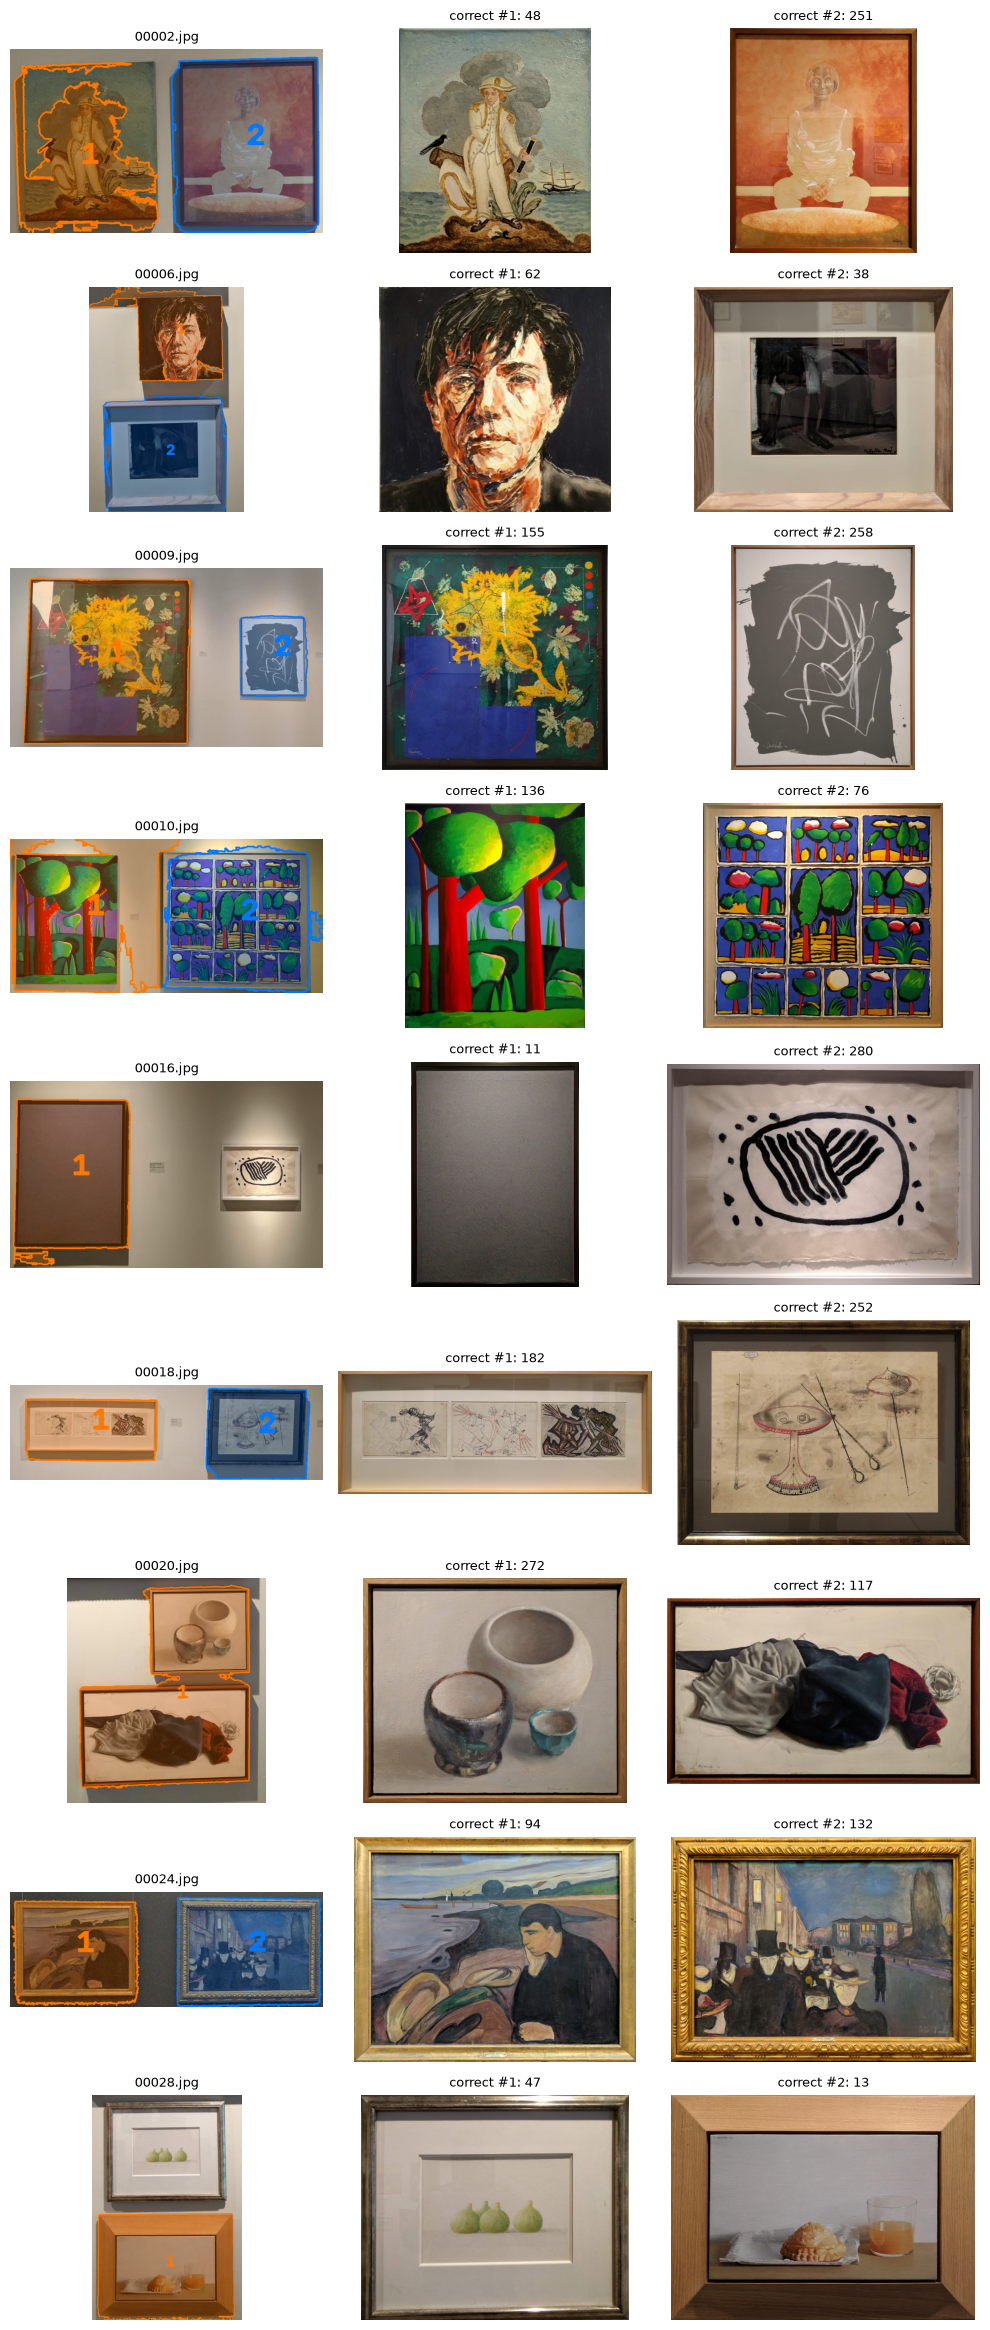

In [42]:
two = [i for i, g in enumerate(qsd1_gt) if len(g) >= 2]
fig, axes = plt.subplots(len(two), 3, figsize=(10, 2.6 * len(two)), squeeze=False)
for row, i in enumerate(two):
    axes[row, 0].imshow(draw_regions(qsd1_imgs[i], qsd1_regions[i]))
    axes[row, 0].set_title(qsd1_files[i], fontsize=9)
    for col, b in enumerate(qsd1_gt[i][:2]):
        ax = axes[row, col + 1]
        if b == -1:
            ax.text(0.5, 0.5, "not in the museum", ha="center", va="center", transform=ax.transAxes)
        else:
            ax.imshow(cv2.cvtColor(bbdd_imgs[bbdd_index[b]], cv2.COLOR_BGR2RGB))
        ax.set_title(f"correct #{col + 1}: {b}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "pipeline_gt_order.png"), dpi=90, bbox_inches="tight")
plt.show()

- When the paintings are side by side, "correct #1" is always the left one, as in Week 3.
- When one painting is above the other (00006, 00020, 00028), "correct #1" is always the top one, so `ORDER = "auto"` follows the same order as `gt_corresps.pkl`.
- On QSD1-W4 the Week 3 order (left edge) gives the same result, but in 00006 only by chance: the two paintings start at almost the same left edge, and some wall pixels stuck to the top painting make it start a bit more to the left. On the test set a pair like this could come out in the wrong order.
- In 00020 and 00028 only one painting is found, so the order cannot help: the one we find is compared with "correct #1".

### Painting crops

Input of the local descriptors: `qsd1_crops[i]` is the list of painting crops (BGR, left to right) of photo `i`, cut from the denoised photo. The museum images are used as they are (`bbdd_imgs`). `preprocess()` runs the whole common pipeline on a new photo (used for QST1-W4).

In [43]:
def preprocess(img):
    #common pipeline for one photo -> (denoised photo, painting masks left to right, painting crops)
    den = denoise(img)
    regions = segment_paintings(den)
    return den, regions, [bbox_crop(den, r) for r in regions]

qsd1_crops = [[bbox_crop(img, r) for r in regions] for img, regions in zip(qsd1_denoised, qsd1_regions)]
print("paintings per photo:", pd.Series([len(c) for c in qsd1_crops]).value_counts().sort_index().to_dict())
sizes = np.array([c.shape[:2] for cc in qsd1_crops for c in cc])
print(f"crop height {sizes[:, 0].min()}-{sizes[:, 0].max()} px, width {sizes[:, 1].min()}-{sizes[:, 1].max()} px")

paintings per photo: {1: 23, 2: 7}
crop height 198-3613 px, width 235-3547 px


### Output format and evaluation

Every local-descriptor method only has to provide a `score_fn(crop)` that returns one score per BBDD image (same order as `bbdd_ids`, higher = more similar, e.g. the number of good matches). `predict_paintings()` turns the scores into the output format:

- top-10 BBDD ids (integers) of every painting, sorted by score;
- `[-1]` if the best score is below `min_score` (painting not in the museum); `min_score=None` never returns `[-1]`.

Evaluation:

- map@k: one AP per painting, comparing the i-th correct painting with the i-th detected one (a painting that is not detected counts as 0). An unknown painting counts as correct only if its prediction is `[-1]`.
- F1 of the unknown detection: positive class = painting not in the museum (correct answer `-1`), to choose the threshold on the number of matches.

In [44]:
UNKNOWN = -1
K = 10

def apk(actual, predicted, k=10):
    #average precision at k for one query (actual = list of correct bbdd ids)
    predicted = list(predicted)[:k]
    score, hits = 0.0, 0
    for i, p in enumerate(predicted):
        if p in actual and p not in predicted[:i]:
            hits += 1
            score += hits / (i + 1)
    return score / min(len(actual), k) if actual else 0.0

def mapk(actual, predicted, k=10):
    return np.mean([apk(a, p, k) for a, p in zip(actual, predicted)])

def painting_mapk(actual, predicted, k=10):
    #actual / predicted: for every photo, one entry per painting
    aps = []
    for a_img, p_img in zip(actual, predicted):
        for j, a in enumerate(a_img):
            aps.append(apk([a], p_img[j], k) if j < len(p_img) else 0.0)
    return np.mean(aps)

def unknown_f1(actual, predicted):
    #precision / recall / F1 of the unknown detection, painting by painting (positive = not in the museum)
    tp = fp = fn = 0
    for a_img, p_img in zip(actual, predicted):
        for j in range(max(len(a_img), len(p_img))):
            is_unk = j < len(a_img) and a_img[j] == UNKNOWN
            said_unk = j < len(p_img) and list(p_img[j]) == [UNKNOWN]
            tp += is_unk and said_unk
            fp += said_unk and not is_unk
            fn += is_unk and not said_unk
    p, r = tp / (tp + fp + EPS), tp / (tp + fn + EPS)
    return p, r, 2 * p * r / (p + r + EPS)

def rank_to_output(scores, min_score=None, k=K):
    #scores: one value per BBDD image (higher = more similar) -> k integer bbdd ids, or [-1] if unknown
    scores = np.asarray(scores, dtype=np.float64)
    if min_score is not None and scores.max() < min_score:
        return [UNKNOWN]
    return [int(b) for b in bbdd_ids[np.argsort(-scores, kind="stable")[:k]]]

def predict_paintings(crops, score_fn, min_score=None, k=K):
    #crops: for every photo, its painting crops -> for every photo, one output list per painting
    return [[rank_to_output(score_fn(c), min_score, k) for c in cc] for cc in crops]

def check_submission(preds, n_photos, k=K):
    assert len(preds) == n_photos, "one entry per photo"
    for photo in preds:
        assert len(photo) >= 1, "at least one painting per photo"
        for painting in photo:
            assert painting == [UNKNOWN] or (len(painting) == min(k, len(bbdd_ids)) and all(type(i) is int for i in painting)), \
                "k integer ids per painting, or [-1]"

## TASK 1 & 2: Keypoints, local descriptors and matching

All the methods use the same input (`qsd1_crops`, `bbdd_imgs`) and the same output (`score_fn` → `predict_paintings`), so they can be compared directly.

### SIFT

DoG keypoint detector + SIFT descriptor. Matching with L2 distance + Lowe's ratio test (1st / 2nd best match). Score of a BBDD image = number of matches that pass the test.

### ORB

FAST keypoints + BRIEF binary descriptor. Matching with Hamming distance + bidirectional matching (`crossCheck`).

### Third descriptor

### Comparison of the descriptors

Speed, number of keypoints, robustness to noise and colour changes.

### Similarity metrics

L2 vs Hamming, ratio test vs cross-check.

### Unknown detection

Threshold on the number of matches (`min_score`), chosen by optimizing the F1 of the unknown detection on QSD1-W4.

## TASK 3: Evaluation on QSD1-W4 and comparison with the best Week 3 system

Best Week 3 system: denoising + painting detection + LBP 8x8 with radii 1, 2, 3 (P=8), L1 distance.

## TASK 4: Blind submission (QST1-W4)

Only the best method (`method1`), with `[-1]` for unknown paintings. Nothing is tuned on the test set.